# Comparing the models

The EDA showed that issue readings are rare and that some component sensors differ between labels. I now compare six model families on the same vehicle groups.

I expect their mistakes to differ. A model that finds many issues may also raise more false alerts. A model with fewer alerts may miss some issues. I use precision, recall, F1 and average precision to examine that balance.


## Data and libraries

The analysis uses Python for data preparation, modelling and visualization. The dataset and saved results share one project folder. Colab stores this folder in Google Drive, while a local Jupyter session uses the same layout.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import subprocess
from importlib.metadata import version, PackageNotFoundError
from urllib.request import urlretrieve

packages = {
    "numpy": "2.2.6", "pandas": "2.3.3", "scipy": "1.16.2",
    "scikit-learn": "1.7.2", "xgboost": "3.0.5",
    "imbalanced-learn": "0.14.0", "matplotlib": "3.10.6",
    "seaborn": "0.13.2", "openpyxl": "3.1.5", "joblib": "1.6.0"
}
install = []
for package, required in packages.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if installed != required:
        install.append(f"{package}=={required}")
if install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *install])

try:
    from google.colab import drive
except ImportError:
    project = Path.cwd()
    if project.name == "notebooks":
        project = project.parent
else:
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/Automotive_Component_Failure")

for folder in ["data", "models/baseline", "models/follow_up",
               "results/tables", "results/figures", "results/predictions", "results/recorded"]:
    (project / folder).mkdir(parents=True, exist_ok=True)

source = "https://raw.githubusercontent.com/PrasadKolkar/critical-automotive-component-failure/main"
files = {
    "data/synthetic_telemetry_data.xlsx": "data/synthetic_telemetry_data.xlsx",
    "data/vehicle_folds.csv": "data/vehicle_folds.csv"
}
for name in ["model_comparison.csv", "oof_predictions.csv", "representation_comparison.csv",
             "augmentation_comparison.csv", "confusion_counts.csv"]:
    files["results/recorded/" + name] = "results/recorded/" + name
for name in ["feature_importance.csv", "descriptive_subtype_rules.json", "reconstruction_comparison.json"]:
    files["results/recorded/" + name] = "results/recorded/" + name
for destination, original in files.items():
    if not (project / destination).exists():
        temporary = (project / destination).with_suffix(".download")
        urlretrieve(f"{source}/{original}", temporary)
        temporary.replace(project / destination)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
figures = project / "results/figures"
tables = project / "results/tables"
recorded = project / "results/recorded"
print("Project files ready.")


Project files ready.


In [2]:
data_path = project / "data/synthetic_telemetry_data.xlsx"
fold_path = project / "data/vehicle_folds.csv"
expected_hashes = {
    data_path: "569d9f3bfd57f25e2ee7b0d4176fd22b8b8e4aa9a1cf5dab30b57517a4950cc3",
    fold_path: "3f9d35b1ba22f124fe4ef11da399b1abe6d8978257025e5cbe7b79b4422b4b1e"
}
for path, expected in expected_hashes.items():
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError(f"The study file has changed: {path.name}")

df = pd.read_excel(data_path)
component_labels = ["engine_failure_imminent", "brake_issue_imminent", "battery_issue_imminent"]
target = "any_imminent_issue"
df[target] = df[component_labels].max(axis=1).astype(int)
vehicle_folds = pd.read_csv(fold_path)
fold_for_row = df.vehicle_id.map(vehicle_folds.set_index("vehicle_id").fold)
assert vehicle_folds.vehicle_id.is_unique
assert set(vehicle_folds.vehicle_id) == set(df.vehicle_id)
assert len(df) == 1970 and df.vehicle_id.nunique() == 50 and df[target].sum() == 35
assert not fold_for_row.isna().any()
print(f"{len(df):,} readings from {df.vehicle_id.nunique()} vehicles")
print(f"{df[target].sum()} issue-labelled readings from {df.loc[df[target].eq(1), 'vehicle_id'].nunique()} vehicles")


1,970 readings from 50 vehicles
35 issue-labelled readings from 25 vehicles


## Preparing the measurements

I combine the engine, brake and battery labels into one outcome. Failure date, failure type and the original issue flags reveal that outcome, so I leave them out of the inputs. Vehicle ID keeps the groups together. Brand is encoded as categories. Scaling and other fitted steps use training readings only.


In [3]:
import time
import warnings
from itertools import product
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             confusion_matrix, precision_recall_curve)
from sklearn.model_selection import ParameterGrid
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from threadpoolctl import threadpool_limits

excluded = ["vehicle_id", "timestamp", "failure_date", "failure_type", target, *component_labels]
predictors = [column for column in df.columns if column not in excluded + ["abs_fault_indicator"]]
numeric_columns = df[predictors].select_dtypes(include="number").columns.tolist()
categorical_columns = ["brand"]
assert len(numeric_columns) == 32 and len(predictors) == 33
print("Predictors:", len(numeric_columns), "numeric measurements and brand")


Predictors: 32 numeric measurements and brand


## Keeping vehicles together

I use five fixed vehicle groups. Each round holds out ten vehicles and seven issue readings. Within the remaining vehicles, three smaller groups help choose the model settings.


In [4]:
split_summary = pd.DataFrame({"fold": fold_for_row, "vehicle": df.vehicle_id, "issues": df[target]})
display(split_summary.groupby("fold").agg(readings=("vehicle", "size"), vehicles=("vehicle", "nunique"), issues=("issues", "sum")))


,readings,vehicles,issues
fold,,,
1,396,10,7
2,396,10,7
3,393,10,7
4,393,10,7
5,392,10,7


In [5]:
def grouped_splits(frame, n_splits=3):
    summary = (frame.groupby("vehicle_id").agg(rows=(target, "size"), positives=(target, "sum"))
               .reset_index().sort_values(["positives", "rows", "vehicle_id"], ascending=[False, False, True]))
    groups = [[] for _ in range(n_splits)]
    positive_counts = [0] * n_splits
    row_counts = [0] * n_splits
    for row in summary.itertuples():
        fold = min(range(n_splits), key=lambda i: (positive_counts[i], row_counts[i], len(groups[i])))
        groups[fold].append(row.vehicle_id)
        positive_counts[fold] += row.positives
        row_counts[fold] += row.rows
    splits = []
    for vehicles in groups:
        validation = frame.vehicle_id.isin(vehicles).to_numpy()
        train_index = np.flatnonzero(~validation)
        valid_index = np.flatnonzero(validation)
        assert set(frame.iloc[train_index].vehicle_id).isdisjoint(frame.iloc[valid_index].vehicle_id)
        assert frame.iloc[train_index][target].nunique() == frame.iloc[valid_index][target].nunique() == 2
        splits.append((train_index, valid_index))
    return splits


def evaluate(y, scores):
    predicted = (np.asarray(scores) >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0),
            "F1": f1_score(y, predicted, zero_division=0),
            "AP": average_precision_score(y, scores),
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}


## Model settings

I compare a linear model, two tree models, SVM, Naive Bayes and a small neural network. The candidate settings follow the study. The ANN grid tries 16 or 32 hidden units and two regularization values.


In [6]:
model_settings = {
    "LR": [dict(C=c, class_weight="balanced", solver="liblinear", max_iter=1000, random_state=42)
           for c in [0.1, 1.0, 10.0]],
    "RF": [
        dict(n_estimators=200, max_depth=4, min_samples_leaf=2, max_features="sqrt",
             class_weight="balanced", random_state=42, n_jobs=1),
        dict(n_estimators=300, max_depth=6, min_samples_leaf=3, max_features="sqrt",
             class_weight="balanced", random_state=42, n_jobs=1),
        dict(n_estimators=300, max_depth=None, min_samples_leaf=5, max_features="sqrt",
             class_weight="balanced_subsample", random_state=42, n_jobs=1)
    ],
    "XGB": [
        dict(n_estimators=80, max_depth=2, learning_rate=.08, subsample=.9, colsample_bytree=.9,
             min_child_weight=1, reg_alpha=0., reg_lambda=1., random_state=42, eval_metric="logloss", n_jobs=1),
        dict(n_estimators=120, max_depth=3, learning_rate=.05, subsample=.9, colsample_bytree=.8,
             min_child_weight=2, reg_alpha=0., reg_lambda=2., random_state=42, eval_metric="logloss", n_jobs=1),
        dict(n_estimators=160, max_depth=2, learning_rate=.04, subsample=.8, colsample_bytree=.8,
             min_child_weight=3, reg_alpha=.1, reg_lambda=2., random_state=42, eval_metric="logloss", n_jobs=1)
    ],
    "SVM": [dict(C=c, kernel="rbf", gamma="scale", class_weight="balanced", probability=False, random_state=42)
            for c in [.1, 1., 10.]] + [dict(C=1., kernel="linear", gamma="scale", class_weight="balanced", probability=False, random_state=42)],
    "NB": [dict(var_smoothing=value) for value in [1e-9, 1e-6, 1e-3]],
    "ANN": [dict(alpha=alpha, hidden_layer_sizes=(units,), solver="lbfgs", activation="relu",
                 max_iter=1000, max_fun=20000, tol=1e-4, early_stopping=False, random_state=42)
            for alpha in [.1, 1.] for units in [16, 32]]
}

model_names = {"LR": "Logistic Regression", "RF": "Random Forest", "XGB": "XGBoost",
               "SVM": "SVM", "NB": "Naive Bayes", "ANN": "ANN"}


def experiment(model, representation="original", include_abs=False, sampler="none", seed=42, weighted=True):
    if model == "NB":
        weighted = False
    params = [p.copy() for p in model_settings[model]]
    if model == "LR":
        params = [dict(p, class_weight="balanced" if weighted else None) for p in params]
    representations = {"original": [None], "selection": [10, 20], "pca": [.90, .95]}[representation]
    ratios = [.10, .25] if sampler != "none" else [None]
    candidates = [{"params": p, "representation_value": r, "ratio": ratio}
                  for p, r, ratio in product(params, representations, ratios)]
    suffix = "abs" if include_abs else "noabs"
    weight_name = "weighted" if weighted else "unweighted"
    identifier = f"{model.lower()}_{suffix}_{representation}_{sampler}_{weight_name}"
    if sampler != "none":
        identifier += f"_seed{seed}"
    name = model_names[model]
    if representation != "original":
        name += " + " + ("selected sensors" if representation == "selection" else "PCA")
    if include_abs:
        name += " + ABS"
    if sampler != "none":
        name += f" + {sampler} (seed {seed})"
    folder = "baseline" if representation == "original" and not include_abs and sampler == "none" and (weighted or model == "NB") else "follow_up"
    return dict(id=identifier, name=name, model=model, representation=representation, abs=include_abs,
                sampler=sampler, seed=seed, weighted=weighted, candidates=candidates, folder=folder)


baseline_configs = [experiment(model) for model in model_names]


## Preparing and fitting each model

Logistic Regression, SVM, Naive Bayes and ANN use scaled numerical inputs. Trees use the original scale. I select sensors or apply PCA inside the numerical pipeline when the experiment calls for it.


In [7]:
def prepare_inputs(config, candidate):
    numbers = numeric_columns + (["abs_fault_indicator"] if config["abs"] else [])
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if config["model"] not in ["RF", "XGB"]:
        steps.append(("scaler", StandardScaler()))
    if config["representation"] == "selection":
        steps.append(("representation", SelectKBest(f_classif, k=candidate["representation_value"])))
    elif config["representation"] == "pca":
        steps.append(("representation", PCA(n_components=candidate["representation_value"], svd_solver="full")))
    categories = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("numeric", Pipeline(steps), numbers),
                              ("brand", categories, categorical_columns)], sparse_threshold=0)


In [8]:
FIT_COUNT = 0


def fit_model(training, config, candidate):
    global FIT_COUNT
    columns = predictors + (["abs_fault_indicator"] if config["abs"] else [])
    X, y = training[columns], training[target].to_numpy()
    params = candidate["params"].copy()
    preprocessing = prepare_inputs(config, candidate)
    with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
        warnings.simplefilter("always")
        if config["model"] == "SVM":
            pipeline = Pipeline([("preprocess", preprocessing), ("model", SVC(**params))])
            fitted = CalibratedClassifierCV(estimator=pipeline, cv=grouped_splits(training),
                                           method="sigmoid", ensemble=False, n_jobs=1)
            fitted.fit(X, y)
        else:
            if config["model"] == "XGB":
                params["scale_pos_weight"] = float((y == 0).sum() / (y == 1).sum()) if config["weighted"] else 1.0
            constructors = {"LR": LogisticRegression, "RF": RandomForestClassifier,
                            "XGB": XGBClassifier, "NB": GaussianNB, "ANN": MLPClassifier}
            estimator = constructors[config["model"]](**params)
            preprocessing.fit(X, y)
            X_fit, y_fit = X, y
            if config["sampler"] != "none":
                X_fit, y_fit = add_training_examples(training, config, candidate["ratio"])
            weights = {}
            if config["model"] == "ANN" and config["weighted"]:
                weights["sample_weight"] = compute_sample_weight("balanced", y_fit)
            estimator.fit(preprocessing.transform(X_fit), y_fit, **weights)
            fitted = Pipeline([("preprocess", preprocessing), ("model", estimator)])
    FIT_COUNT += 1
    messages = [f"{w.category.__name__}: {w.message}" for w in caught]
    return fitted, messages


def predict(model, readings, config):
    columns = predictors + (["abs_fault_indicator"] if config["abs"] else [])
    with threadpool_limits(limits=1):
        scores = model.predict_proba(readings[columns])[:, 1]
    assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
    return scores


## Selecting and saving the models

For each fold, I choose settings by average precision, followed by F1 and recall. The chosen model then predicts the held-out vehicles. I save each fitted model with its preprocessing and selected settings. These saved fits support repeated evaluation and example predictions.


In [9]:
data_signature = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in expected_hashes}
actual_versions = {name: version(name) for name in packages}
(project / "environment.json").write_text(json.dumps({"python": sys.version, "packages": actual_versions}, indent=2))


def run_experiment(config):
    folder = project / "models" / config["folder"] / config["id"]
    folder.mkdir(parents=True, exist_ok=True)
    signature = hashlib.sha256(json.dumps({"config": config, "data": data_signature,
                                          "packages": actual_versions}, sort_keys=True).encode()).hexdigest()
    fold_predictions, fold_metrics, choices, search_results, training_warnings = [], [], [], [], []
    trained_count, loaded_count = 0, 0
    for fold in range(1, 6):
        path = folder / f"fold_{fold}.joblib"
        test_mask = fold_for_row.eq(fold)
        training, test = df.loc[~test_mask], df.loc[test_mask]
        assert set(training.vehicle_id).isdisjoint(test.vehicle_id)
        if path.exists():
            saved = joblib.load(path)
            if saved["signature"] != signature:
                raise ValueError("Saved models use different study settings or package versions. Use the listed requirements.")
            assert saved["training_rows"] == training.index.tolist()
            assert saved["test_rows"] == test.index.tolist()
            loaded_count += 1
        else:
            inner_splits = grouped_splits(training)
            candidate_results = []
            for number, candidate in enumerate(config["candidates"]):
                scores = []
                for train_index, valid_index in inner_splits:
                    inner_train, validation = training.iloc[train_index], training.iloc[valid_index]
                    fitted, messages = fit_model(inner_train, config, candidate)
                    result = evaluate(validation[target], predict(fitted, validation, config))
                    scores.append(result)
                means = {key: float(np.mean([row[key] for row in scores])) for key in ["AP", "F1", "recall"]}
                candidate_results.append(dict(candidate=number, **means))
            best = max(candidate_results, key=lambda row: (row["AP"], row["F1"], row["recall"], -row["candidate"]))
            choice = config["candidates"][best["candidate"]]
            fitted, messages = fit_model(training, config, choice)
            saved = {"signature": signature, "model": fitted, "config": config, "choice": choice,
                     "training_rows": training.index.tolist(), "test_rows": test.index.tolist(),
                     "search_results": candidate_results, "warnings": messages}
            temporary = path.with_suffix(".tmp")
            joblib.dump(saved, temporary)
            temporary.replace(path)
            trained_count += 1
        scores = predict(saved["model"], test, config)
        fold_metrics.append(dict(fold=fold, **evaluate(test[target], scores)))
        fold_predictions.append(pd.DataFrame({"row_index": test.index, "vehicle_id": test.vehicle_id.to_numpy(),
            "fold": fold, "actual": test[target].to_numpy(), "score": scores, "predicted": (scores >= .5).astype(int)}))
        choices.append(dict(fold=fold, choice=saved["choice"]))
        search_results.extend(dict(fold=fold, **row) for row in saved["search_results"])
        training_warnings.extend(dict(fold=fold, warning=message) for message in saved["warnings"])
    predictions = pd.concat(fold_predictions).sort_values("row_index").reset_index(drop=True)
    assert predictions.row_index.tolist() == df.index.tolist()
    summary = dict(id=config["id"], model=config["model"], name=config["name"],
                   **evaluate(predictions.actual, predictions.score))
    predictions.to_csv(project / "results/predictions" / f"{config['id']}.csv", index=False)
    pd.DataFrame(fold_metrics).to_csv(tables / f"{config['id']}_folds.csv", index=False)
    pd.DataFrame(search_results).to_csv(tables / f"{config['id']}_search.csv", index=False)
    pd.DataFrame(training_warnings, columns=["fold", "warning"]).to_csv(tables / f"{config['id']}_warnings.csv", index=False)
    (tables / f"{config['id']}_settings.json").write_text(json.dumps(choices, indent=2))
    print(f"{config['name']}: {trained_count} folds trained, {loaded_count} loaded.")
    return summary, predictions


## Training the six models

I evaluate each model family across all five vehicle groups. Every reading receives one prediction while its vehicle is held out. The table combines these predictions to compare the models.


In [10]:
started = time.perf_counter()
model_results, predictions_by_model = [], {}
fits_before = FIT_COUNT
for config in baseline_configs:
    result, predictions = run_experiment(config)
    model_results.append(result)
    predictions_by_model[config["model"]] = predictions
results = pd.DataFrame(model_results)
results.to_csv(tables / "model_comparison.csv", index=False)
display(results[["name", "precision", "recall", "F1", "AP", "TP", "FP", "FN"]].round(4))
print(f"Finished in {time.perf_counter() - started:.1f} seconds. New training calls: {FIT_COUNT - fits_before}")


Logistic Regression: 0 folds trained, 5 loaded.


Random Forest: 0 folds trained, 5 loaded.


XGBoost: 0 folds trained, 5 loaded.
SVM: 0 folds trained, 5 loaded.
Naive Bayes: 0 folds trained, 5 loaded.


ANN: 0 folds trained, 5 loaded.


,name,precision,recall,F1,AP,TP,FP,FN
0,Logistic Regression,0.3232,0.9143,0.4776,0.8427,32,67,3
1,Random Forest,1.0000,0.2857,0.4444,0.9656,10,0,25
2,XGBoost,0.8293,0.9714,0.8947,0.9730,34,7,1
3,SVM,0.9189,0.9714,0.9444,0.9896,34,3,1
4,Naive Bayes,0.3444,0.8857,0.4960,0.8747,31,59,4
5,ANN,0.8947,0.9714,0.9315,0.9895,34,4,1


Finished in 0.4 seconds. New training calls: 0


## Comparing detections and false alerts

Precision measures how many alerts match an issue label. Recall measures how many of the 35 issue readings are found. F1 combines them. Average precision examines the ordering of scores across cutoffs.


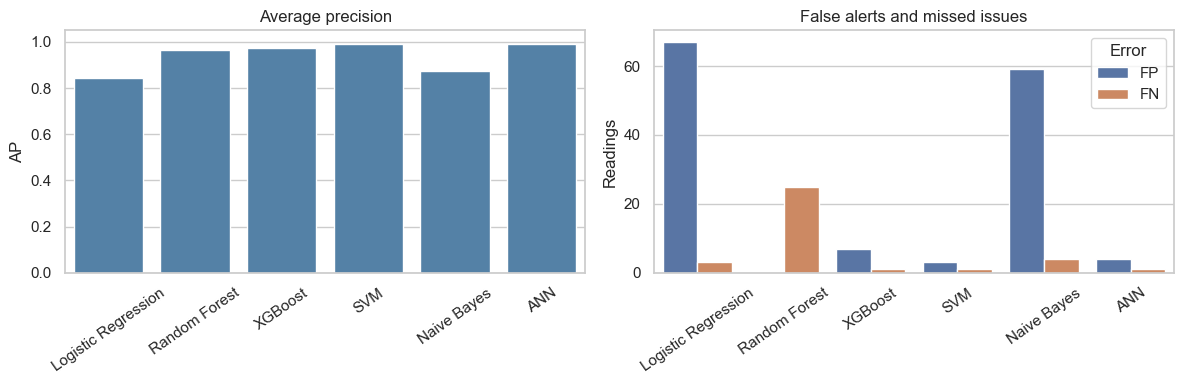

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=results, x="name", y="AP", ax=axes[0], color="steelblue")
axes[0].set(title="Average precision", xlabel="", ylim=(0, 1.05))
error_counts = results.melt(id_vars="name", value_vars=["FP", "FN"], var_name="Error", value_name="Readings")
sns.barplot(data=error_counts, x="name", y="Readings", hue="Error", ax=axes[1])
axes[1].set(title="False alerts and missed issues", xlabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig(figures / "model_comparison.png", dpi=180)
plt.show()


The plots show the current run. I read the error counts beside the scores, because a high accuracy can hide missed issues. All six models are judged on the same 1,970 readings.


## Confusion matrices

The diagonal contains correct decisions. The top-right cell counts false alerts, and the bottom-left cell counts missed issues. Colour is normalized within each actual class so the rare issue row remains visible.


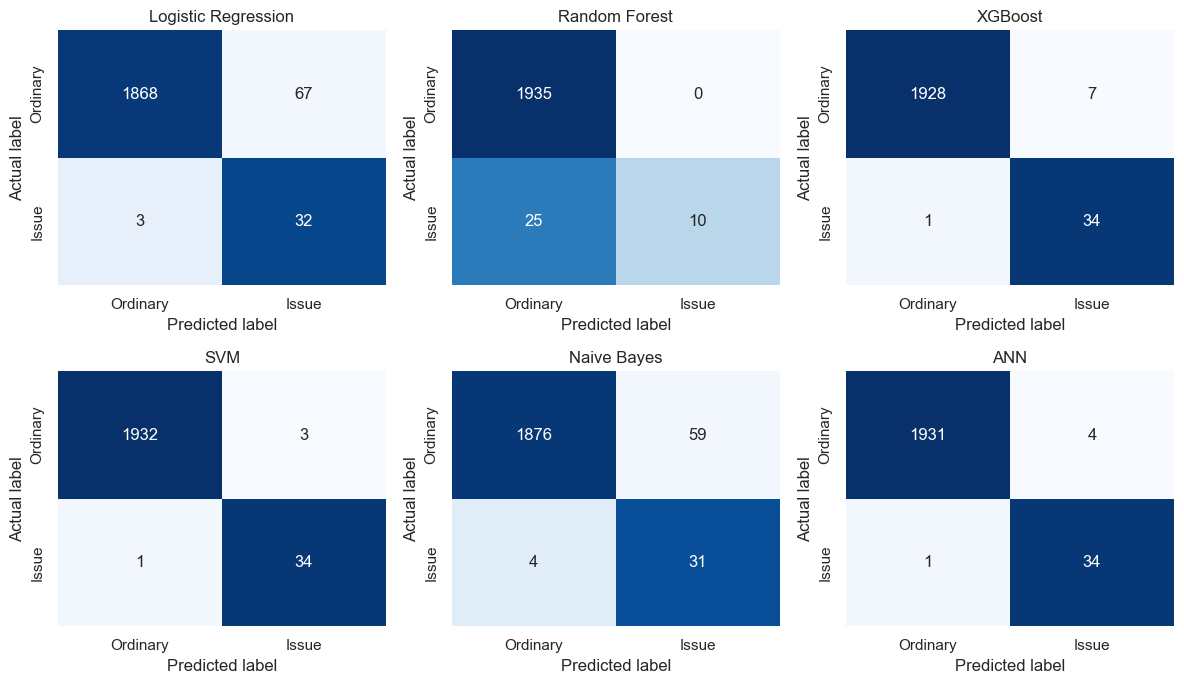

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, config in zip(axes.flat, baseline_configs):
    p = predictions_by_model[config["model"]]
    counts = confusion_matrix(p.actual, p.predicted, labels=[0, 1])
    proportions = counts / counts.sum(axis=1, keepdims=True)
    sns.heatmap(proportions, annot=counts, fmt="d", cmap="Blues", vmin=0, vmax=1,
                cbar=False, xticklabels=["Ordinary", "Issue"], yticklabels=["Ordinary", "Issue"], ax=ax)
    ax.set(title=config["name"], xlabel="Predicted label", ylabel="Actual label")
plt.tight_layout()
plt.savefig(figures / "confusion_matrices.png", dpi=180)
plt.show()


## Precision and recall across cutoffs

Moving right means finding more issues. A fall in precision means that additional alerts include more ordinary readings. The curve helps explain how the fixed 0.5 decisions relate to the model's ranking.


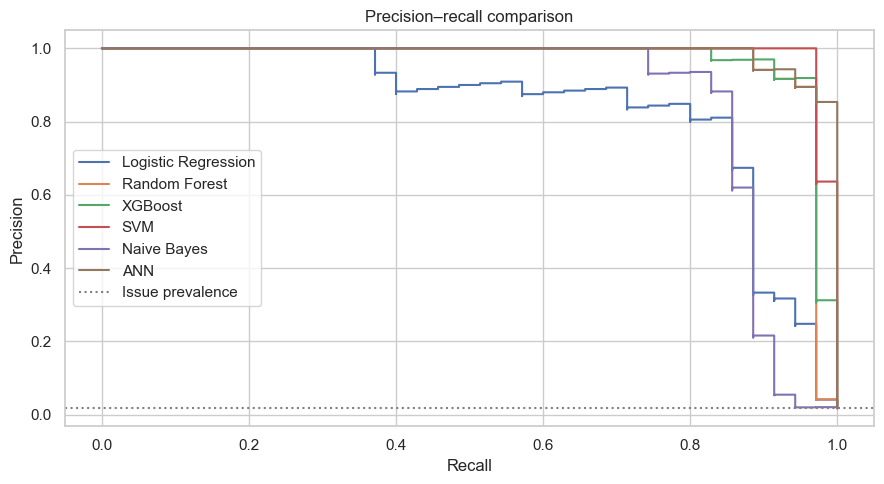

In [13]:
plt.figure(figsize=(9, 5))
for config in baseline_configs:
    p = predictions_by_model[config["model"]]
    precision, recall, _ = precision_recall_curve(p.actual, p.score)
    plt.step(recall, precision, where="post", label=config["name"])
plt.axhline(df[target].mean(), color="grey", linestyle=":", label="Issue prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–recall comparison")
plt.legend()
plt.tight_layout()
plt.savefig(figures / "precision_recall.png", dpi=180)
plt.show()


## Connecting this run with the report

The report uses the recorded study results. This notebook fits fresh models and saves them for later use. I compare both below so differences remain visible. The original XGBoost fits were not archived, and later rebuilds changed some predictions.


In [14]:
historical = pd.read_csv(recorded / "model_comparison.csv").set_index("config_id")
report_ids = {"LR": "legacy_lr_noabs", "RF": "legacy_rf_noabs", "XGB": "legacy_xgb_noabs",
              "SVM": "svm_noabs_original_none_weighted", "NB": "gaussiannb_noabs_original_none_unweighted",
              "ANN": "mlp_noabs_original_none_weighted"}
comparison = results[["model", "name", "F1", "AP"]].copy()
comparison["Report F1"] = comparison.model.map(lambda name: historical.loc[report_ids[name], "f1"])
comparison["Report AP"] = comparison.model.map(lambda name: historical.loc[report_ids[name], "average_precision"])
display(comparison.rename(columns={"F1": "Current F1", "AP": "Current AP"}).round(4))


,model,name,Current F1,Current AP,Report F1,Report AP
0,LR,Logistic Regression,0.4776,0.8427,0.4776,0.8427
1,RF,Random Forest,0.4444,0.9656,0.9062,0.9631
2,XGB,XGBoost,0.8947,0.9730,0.9714,0.9939
3,SVM,SVM,0.9444,0.9896,0.9444,0.9896
4,NB,Naive Bayes,0.4960,0.8747,0.4960,0.8747
5,ANN,ANN,0.9315,0.9895,0.9315,0.9895


## What I learned

The useful comparison includes both detections and mistakes. Similar scores can hide different false alerts and missed issues. The current predictions can be inspected individually in the next notebook.

I also examine whether selecting sensors, applying PCA or adding training examples improves the models. The same five vehicle groups are reused during development, so a later independent fleet would be needed for a final test.
